# Chapter 6: k-Nearest Neighbors (k-NN)

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

## 6.1 Introduction & Motivation

As our final classical classifier, we'll explore the k-NN (k-Nearest Neighbors) algorithm. This approach is based on a very simple and logical idea: observations of the same class should resemble each other. In our digit examples, this definitely makes sense, but what does this concretely mean? And how can we tell a computer when things resemble each other?

This and much more is what we'll learn in this chapter! Excited yet?

**Key concept**: k-NN assumes that similar data points belong to the same class and are located close to each other in the feature space.

## 6.2 Problem Setting

Once again, we'll use the familiar digits dataset for our k-NN implementation. The setup should look familiar from previous chapters:

**Note**: We use consistent variable naming (X_train, X_test) following scikit-learn conventions where X represents features and y represents target labels.

Image Data Shape (1797, 64)
Label Data Shape (1797,)


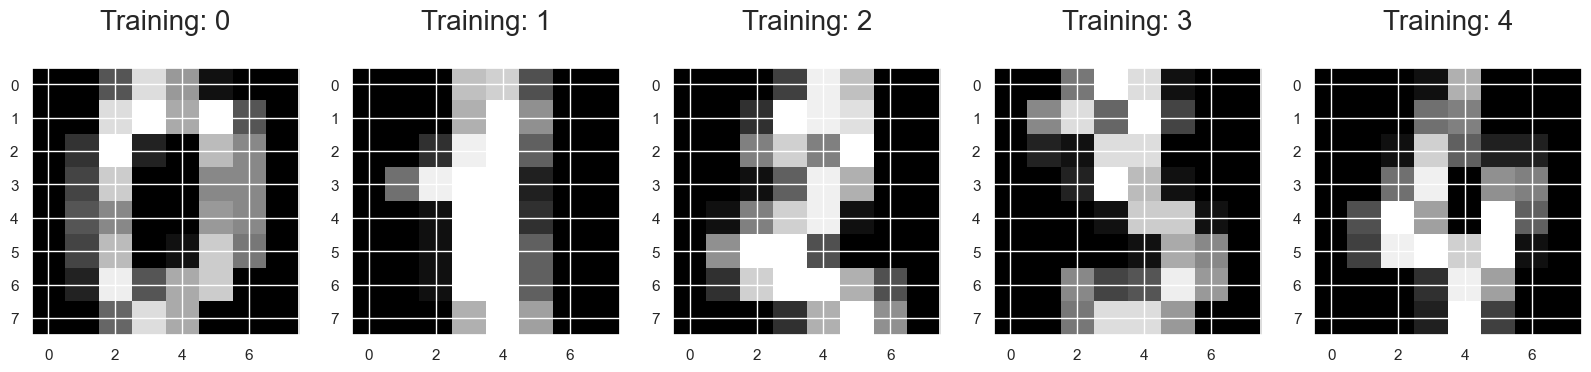

In [2]:
digits = datasets.load_digits()
# Print to show there are 1797 images (8 by 8 images for a dimensionality of 64)
print("Image Data Shape", digits.data.shape)
# Print to show there are 1797 labels (integers from 0-9)
print("Label Data Shape", digits.target.shape)
plt.figure(figsize=(20,4))
for index, (image, label) in enumerate(zip(digits.data[0:5], digits.target[0:5])):
    plt.subplot(1, 5, index + 1)
    plt.imshow(np.reshape(image, (8,8)), cmap=plt.cm.gray)
    plt.title('Training: %i\n' % label, fontsize = 20)
plt.show()
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

## 6.3 Model

### 6.3.1 Model

In our digits database, the independent variables (pixel intensities) are difficult to visualize, so let's look at a simpler 2D dataset to understand how k-NN works conceptually:

![alt text](https://depiesml.files.wordpress.com/2015/08/knn_plot.png?w=600&h=586)

If we want a model to classify this type of data, we'll make use of one very important property of classes of data: **they cluster together in the right dimensions**. That is, in these two variables (F1 and F2), we can clearly see that all the points of the same class are bundled together. On average, we can say that if we take a random blue point, we're more likely to find another blue point nearby rather than a green or red one.

This is exactly what k-NN does: it takes a point we want to predict (for example, the grey point in the next image) and finds its nearest neighbors to make a classification decision.

![alt text](https://depiesml.files.wordpress.com/2015/08/knn-k5-initial1.png?w=600&h=586)

The k-NN algorithm then calculates the distance from the query point to all other points in the training set, and selects the $k$ nearest data points. 

**Note**: The most common distance metric used is Euclidean distance, but other metrics like Manhattan or Minkowski distance can also be used depending on the problem.

![](https://depiesml.files.wordpress.com/2015/08/knn-k5-neighbor.png)

These nearest neighbors then "vote" on which class we should predict for the query point. Different voting schemes are possible, but the most straightforward approach is **majority voting**: the class that is represented the most among the k nearest neighbors becomes the final prediction.

**Example**: If k=5 and we find 3 blue points, 1 red point, and 1 green point as the nearest neighbors, then the prediction would be "blue" since it has the majority vote.

### 6.3.2 Model Estimation

That all sounds straightforward enough, so let's put it into practice!
We'll create a 9-Nearest-Neighbors classifier and fit it to our training data:

**Note**: The choice of k=9 is arbitrary for now. We'll explore how to choose the optimal k value later in this chapter.

In [3]:
neigh = KNeighborsClassifier(n_neighbors=9)
neigh.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=9)

Next, we can make predictions in different ways:
- For a single observation (one image)
- For multiple observations at once
- For all observations in our test set

**Tip**: Notice how we need to reshape single observations using `.reshape(1,-1)` to match the expected input format for scikit-learn.

In [4]:
# predict() returns a NumPy array
# Predict for one observation (image)
print(neigh.predict(X_test[0].reshape(1,-1)))
# Predict for the first 10 observations
print(neigh.predict(X_test[0:10]))
# Predict for the entire test set
predictions = neigh.predict(X_test)

[2]
[2 8 2 6 6 7 1 9 8 5]


## 6.4 Model Evaluation

### 6.4.1 Accuracy

Let's start by evaluating our model's accuracy - the percentage of correct predictions:

In [5]:
# accuracy
# Use score method to get accuracy of model
accuracy = accuracy_score(y_test, predictions)
print(accuracy)

0.9777777777777777


##### Question 1: Experiment with the n_neighbors parameter to find which model gives the highest accuracy. Interpret your findings! Explain what is happening in the model and how the choice of k influences accuracy. Is this behavior logical? Are there any constraints on this parameter?

**Hint**: Try different values of k and observe the pattern. Think about what happens when k is very small (like 1) versus when k is very large.

Best k: 1 with accuracy 0.9911111111111112


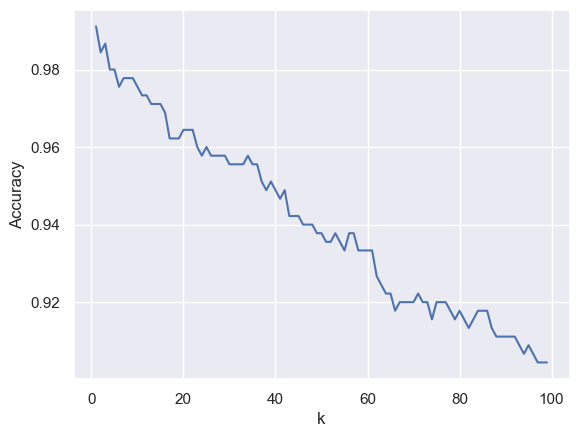

In [6]:
k_values = range(1, 100)
accuracies = []

for k in k_values:
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, neigh.predict(X_test)))

best_k = k_values[np.argmax(accuracies)]
print("Best k:", best_k, "with accuracy", max(accuracies))

plt.plot(k_values, accuracies)
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.show()

We observe a clear downward trend: the highest accuracy is reached at very small values of k (k = 1 gives about 0.991), after which accuracy gradually decreases to about 0.90 at k = 99. The decline is not perfectly linear: it is small and somewhat bumpy for low k and becomes steadier for larger k. This is expected behavior. The higher the value of k, the more neighbors vote on the final label. As k increases, we include neighbors that are farther away from our query point and therefore more likely to belong to a different class, which leads to incorrect predictions.

**Important constraint**: k must be a positive integer and cannot exceed the number of training samples. Our training set contains 1347 digits, so scikit-learn throws an error starting at k = 1348: there are simply not enough neighbors available to vote.

**Key insight**: There's a trade-off with k - too small and the model is sensitive to noise (overfitting), too large and the model becomes too generalized (underfitting). The digits dataset is clean and its classes are well separated, which is why even k = 1 performs very well here. On noisier data, a somewhat larger k usually works better.

##### Going further: visualizing the effect of k

To really understand what k does, let's return to a simple 2D dataset like the one in section 6.3.1. Below we train three k-NN models with a very small, a medium and a very large k. The colored background shows which class the model would predict at every location (the **decision boundary**), while the dots are the training points.

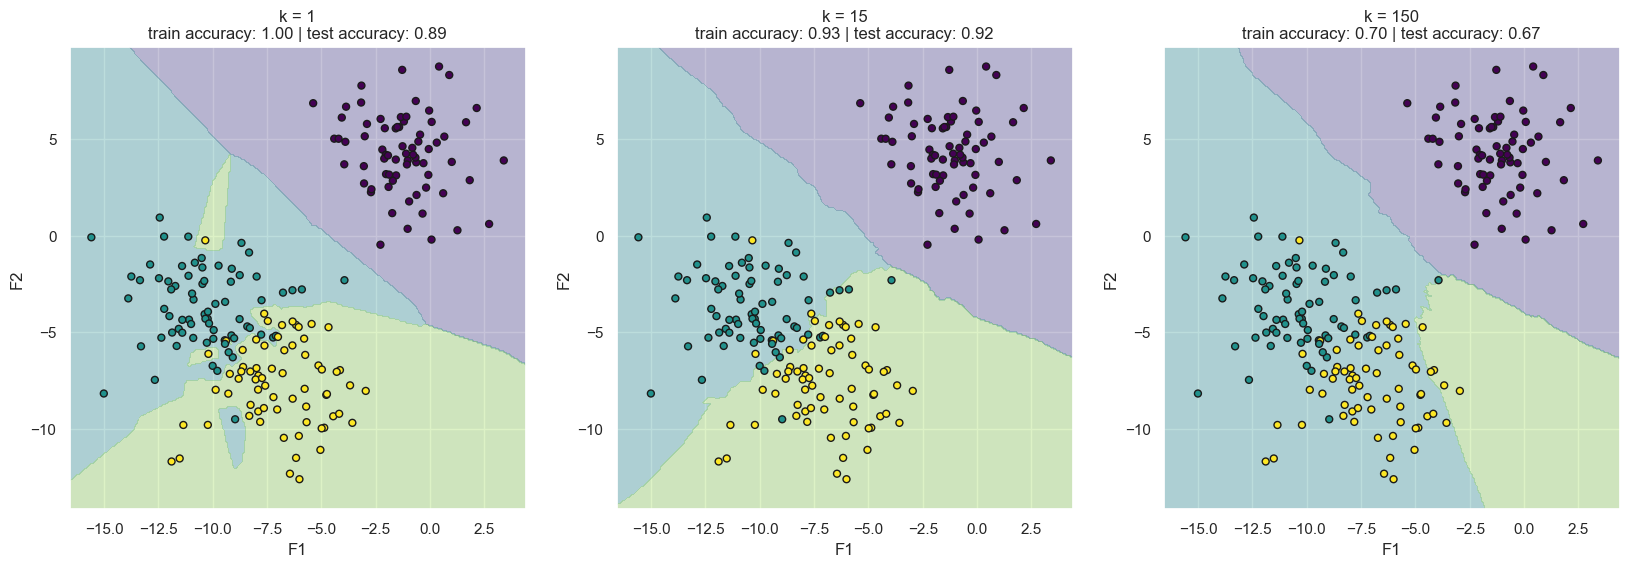

In [7]:
# A 2D toy dataset with 3 overlapping classes
X_blobs, y_blobs = make_blobs(n_samples=300, centers=3, cluster_std=2.0, random_state=1)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_blobs, y_blobs, test_size=0.3, random_state=0)

# A fine grid of points covering the feature space; we predict a class for every grid point
xx, yy = np.meshgrid(np.linspace(X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1, 300),
                     np.linspace(X_blobs[:, 1].min() - 1, X_blobs[:, 1].max() + 1, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, k in zip(axes, [1, 15, 150]):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(Xb_train, yb_train)
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.3, cmap='viridis')
    ax.scatter(Xb_train[:, 0], Xb_train[:, 1], c=yb_train, cmap='viridis', edgecolor='k', s=25)
    ax.set_title('k = %i\ntrain accuracy: %.2f | test accuracy: %.2f'
                 % (k, accuracy_score(yb_train, model.predict(Xb_train)), accuracy_score(yb_test, model.predict(Xb_test))))
    ax.set_xlabel('F1')
    ax.set_ylabel('F2')
plt.show()

- **k = 1**: the decision boundary is very jagged and forms small "islands" around individual points. Every training point is its own nearest neighbor, so the training accuracy is a perfect 1.00, but the test accuracy is clearly lower (0.89). The model follows the noise in the training data: this is **overfitting**.
- **k = 15**: the boundary is smooth and follows the general shape of the classes. Training and test accuracy are both high and close together (0.93 and 0.92).
- **k = 150**: each vote now involves about 70% of all training points, so the class that is simply most common in a large area wins. The boundary no longer follows the data and both training and test accuracy drop sharply (0.70 and 0.67): this is **underfitting**.

We can apply the same idea to our digits: let's compare the accuracy on the **training set** with the accuracy on the **test set** for every k.

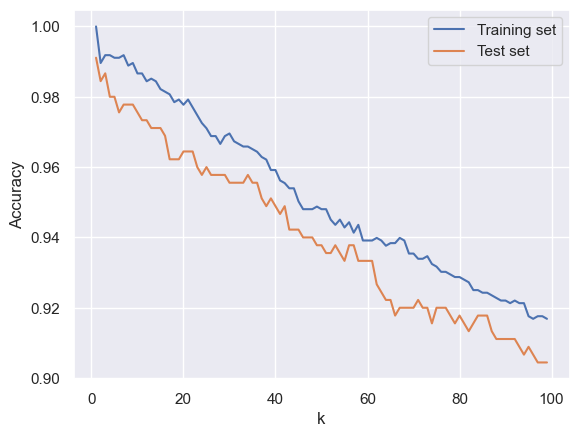

In [8]:
train_accuracies = []
test_accuracies = []

for k in k_values:
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(X_train, y_train)
    train_accuracies.append(accuracy_score(y_train, neigh.predict(X_train)))
    test_accuracies.append(accuracy_score(y_test, neigh.predict(X_test)))

plt.plot(k_values, train_accuracies, label="Training set")
plt.plot(k_values, test_accuracies, label="Test set")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

At k = 1, the training accuracy is exactly 1.0: every training image is its own nearest neighbor, so the model can't get it wrong. This is why **training accuracy is useless for choosing k**: it would always point to k = 1. The test accuracy (0.991) tells us how the model performs on images it has never seen.

For the digits, the gap between the two curves stays small for every k (always around 0.01). This means that overfitting is barely a problem here: the dataset is clean and the classes are well separated. Instead, both curves go down together as k increases (to 0.917 and 0.904 at k = 99), which is the typical sign of **underfitting**: the model becomes too simple and starts averaging away the differences between digits.

### 6.4.2 Precision

Now let's examine precision and other classification metrics using the classification report:

In [9]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       0.93      1.00      0.97        43
           2       1.00      0.98      0.99        44
           3       0.96      1.00      0.98        45
           4       1.00      0.97      0.99        38
           5       0.98      0.98      0.98        48
           6       1.00      1.00      1.00        52
           7       0.94      1.00      0.97        48
           8       1.00      0.88      0.93        48
           9       0.98      0.98      0.98        47

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450



##### Question 2: Experiment with the n_neighbors parameter to see how it affects precision. Interpret your findings! Explain what is happening in the model and how the choice of k influences precision. Is this behavior logical?

**Remember**: Precision measures the proportion of positive predictions that were actually correct (true positives / (true positives + false positives)).

Best k: 1 with precision 0.9912519272278754


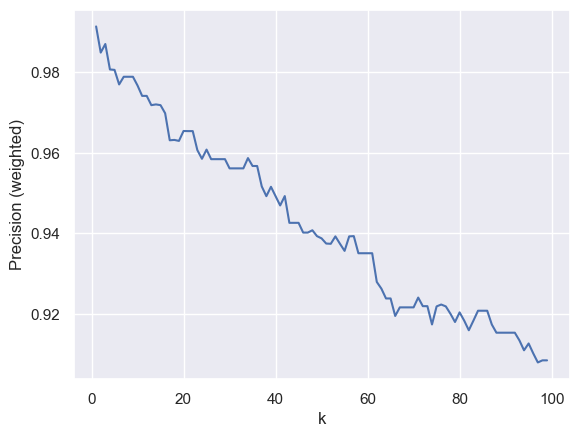

In [10]:
precisions = []

for k in k_values:
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(X_train, y_train)
    precisions.append(precision_score(y_test, neigh.predict(X_test), average='weighted'))

print("Best k:", k_values[np.argmax(precisions)], "with precision", max(precisions))

plt.plot(k_values, precisions)
plt.xlabel("k")
plt.ylabel("Precision (weighted)")
plt.show()

Here we observe the same pattern: precision is highest for small k (about 0.991 at k = 1) and drops to about 0.91 at k = 99. This is expected behavior: as k grows, the votes of distant neighbors from other classes increasingly cause false positives.

**Insight**: Both accuracy and precision follow similar trends with respect to k, which makes sense since they're both measures of prediction quality. Note that we used `average='weighted'`: precision is computed per digit class and then averaged, weighted by the number of test samples per class.

### 6.4.3 Confusion Matrix

You should be familiar with the confusion matrix from previous chapters. Let's create one to visualize our model's performance:

##### Question 3: Create the confusion matrix and interpret it. What does it tell you about your model's performance?

**Reminder**: In a confusion matrix, the diagonal represents correct predictions, while off-diagonal elements represent misclassifications.

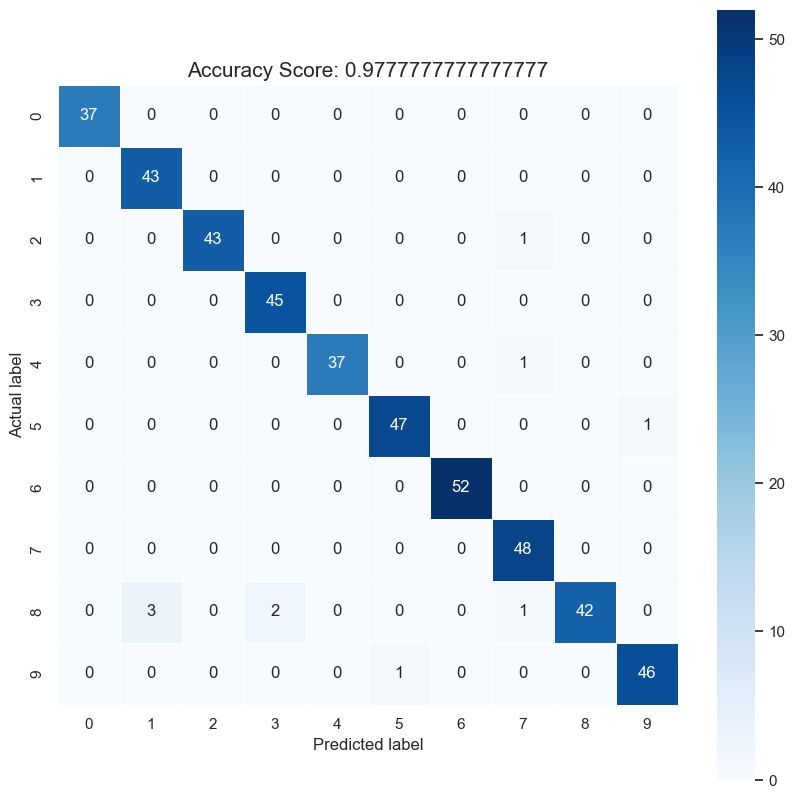

In [11]:
# Refit the k=9 model (the loops above overwrote 'neigh') and recompute its predictions
neigh = KNeighborsClassifier(n_neighbors=9)
neigh.fit(X_train, y_train)
predictions = neigh.predict(X_test)
cm = metrics.confusion_matrix(y_test, predictions)
plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
all_sample_title = 'Accuracy Score: {0}'.format(accuracy_score(y_test, predictions))
plt.title(all_sample_title, size = 15);
plt.show()

This confusion matrix indicates that we have a really good model! We can see:

- **Strong diagonal**: High numbers along the diagonal indicate many correct predictions
- **Few off-diagonal values**: Only 10 of the 450 test images are misclassified
- **Overall pattern**: Most digit classes (0, 1, 3, 6 and 7) are predicted without a single error

**Interpretation**: Most of the errors involve the digit 8. It is mistaken for a 1 three times, for a 3 twice and for a 7 once, which explains its lower recall (0.88) in the classification report. Visually this makes sense: an 8 shares strokes with a 3 and, at a low 8x8 resolution, a thin 8 can resemble a 1. The other errors are isolated: 2 → 7, 4 → 7, 5 → 9 and 9 → 5.

##### Taking a closer look at the mistakes

Numbers only tell part of the story. Let's plot the test images our model got wrong, together with their actual and predicted labels:

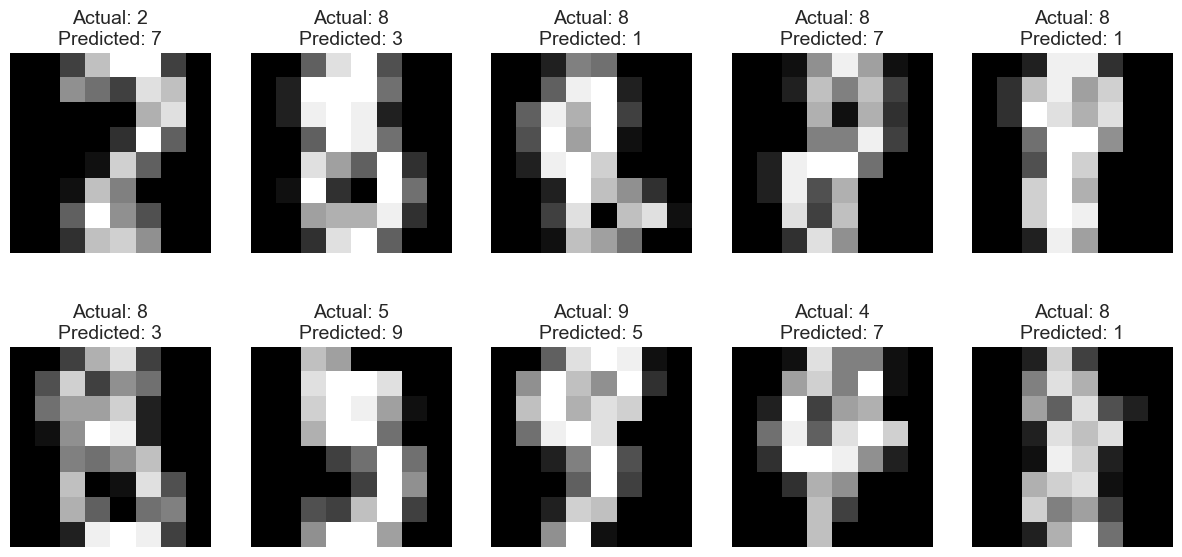

In [12]:
# Indices of the test images where the prediction differs from the actual label
wrong = np.where(predictions != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(np.reshape(X_test[i], (8,8)), cmap=plt.cm.gray)
    ax.set_title('Actual: %i\nPredicted: %i' % (y_test[i], predictions[i]), fontsize=14)
    ax.axis('off')
plt.show()

Many of these images are hard to read, even for a human. At a resolution of only 8x8 pixels, a thin or slanted 8 really does look like a 1 or a 3. Remember that k-NN has no notion of "what an 8 should look like": it simply finds the training images with the most similar pixel values. If a handwritten 8 happens to be closer to a few 1s than to the other 8s, the 1s win the vote.

## 6.5 Exercises

##### Question 1: See section 6.4.1
##### Question 2: See section 6.4.2  
##### Question 3: See section 6.4.3
##### Question 4: Compare the optimal k-NN model to the optimal logistic regression and decision tree models from previous chapters. Which model do you prefer based on accuracy? Which model do you prefer based on precision? Which model would you choose overall? Is there an unambiguous choice to be made?

**Analysis framework**: Consider not just performance metrics, but also factors like:
- Model interpretability
- Training and prediction speed
- Overfitting tendencies
- Computational requirements

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [14]:
accuracies_log, precisions_log = [], []
accuracies_tree, precisions_tree = [], []
accuracies_knn, precisions_knn = [], []

# Small max_iter values deliberately stop before convergence, so we silence those warnings here
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for solver in ['lbfgs', 'saga', 'newton-cg']:
        for max_iter in [10, 100, 1000, 10000]:
            logisticRegr = LogisticRegression(max_iter=max_iter, solver=solver)
            logisticRegr.fit(X_train, y_train)
            pred = logisticRegr.predict(X_test)
            accuracies_log.append(accuracy_score(y_test, pred))
            precisions_log.append(precision_score(y_test, pred, average='weighted'))

for x in range(1, 31):
    model = DecisionTreeClassifier(max_depth=x, random_state=0)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    accuracies_tree.append(accuracy_score(y_test, pred))
    # Very shallow trees never predict some digits; count their precision as 0 instead of warning
    precisions_tree.append(precision_score(y_test, pred, average='weighted', zero_division=0))

for k in k_values:
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(X_train, y_train)
    pred = neigh.predict(X_test)
    accuracies_knn.append(accuracy_score(y_test, pred))
    precisions_knn.append(precision_score(y_test, pred, average='weighted'))

print('Best accuracy  - Logistic regression: %.4f | Decision tree: %.4f | k-NN: %.4f'
      % (max(accuracies_log), max(accuracies_tree), max(accuracies_knn)))
print('Best precision - Logistic regression: %.4f | Decision tree: %.4f | k-NN: %.4f'
      % (max(precisions_log), max(precisions_tree), max(precisions_knn)))

Best accuracy  - Logistic regression: 0.9622 | Decision tree: 0.8444 | k-NN: 0.9911
Best precision - Logistic regression: 0.9631 | Decision tree: 0.8489 | k-NN: 0.9913


When comparing all optimal models, k-NN is the winner on **both accuracy and precision** (about 0.99), followed by logistic regression (about 0.96) and the decision tree (about 0.84-0.85). Since the same model wins on both metrics, the choice is fairly clear for this dataset. This result makes intuitive sense:

**Why k-NN performs well on digits**:
- The digits dataset focuses on the visual/physical shape of handwritten numbers
- k-NN excels at pattern recognition by finding visually similar examples
- Predicting digit classes based on similarity to known examples aligns perfectly with how k-NN works

**Is the choice unambiguous?** Not entirely. Performance isn't the only criterion:
- **Interpretability**: a decision tree (and to a lesser extent logistic regression with its coefficients) is easier to explain than "these 9 training images looked similar"
- **Speed**: k-NN has almost no training time but is slow at prediction time, because it must compute the distance to every training sample; logistic regression and trees predict almost instantly
- **Memory**: k-NN has to store the entire training set, whereas the other models only store their learned parameters

**Important caveat**: We selected the "optimal" hyperparameters (k, max_depth, solver) by looking directly at the **test set** scores. Those best scores are therefore optimistic: we picked whichever setting happened to work best on these particular 450 images. A fairer comparison would split off a separate **validation set** from the training data, use that to choose the hyperparameters, and only evaluate each final model once on the test set. Later on we'll meet *cross-validation*, a more robust version of this idea.

**Next steps**: Consider exploring techniques like:
- A validation set (or cross-validation) to tune hyperparameters
- Feature scaling/normalization
- Different distance metrics
- Ensemble methods combining multiple algorithms